# Experiment: Classification Tree for House Purchase Prediction
**Topic:** Decision Tree Classification  
**Algorithm:** CART (Classification and Regression Trees) with Gini Impurity  
**Objective:** Construct, visualize, and evaluate a binary decision tree classifier to predict whether a customer will purchase a house based on demographic and financial attributes (**Age** and **Income**).

---

## 1. Problem Statement & Theoretical Background

Decision Tree classifiers recursively partition the feature space into axis-aligned rectangular regions. At each internal node, the algorithm selects the feature and split threshold that maximizes the reduction in node impurity.

### Mathematical Formulation

#### Gini Impurity
For a node $t$ with $C$ classes and class probabilities $p(c|t)$:
$$\text{Gini}(t) = 1 - \sum_{c=1}^{C} p(c|t)^2$$

For binary classification ($C=2$), Gini impurity ranges from $0.0$ (pure node, all samples belong to one class) to $0.5$ (maximum uncertainty, uniform class distribution).

#### Information Gain (Impurity Reduction)
Given parent node $t$ and a candidate split partitioning $N_t$ samples into left child $t_L$ ($N_L$ samples) and right child $t_R$ ($N_R$ samples):
$$\Delta \text{Gini}(s, t) = \text{Gini}(t) - \left( \frac{N_L}{N_t} \text{Gini}(t_L) + \frac{N_R}{N_t} \text{Gini}(t_R) \right)$$

The optimal split $s^*$ is selected to maximize $\Delta \text{Gini}(s, t)$.


In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Visual styling
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120


## 2. Dataset Definition & Exploratory Data Analysis

The dataset consists of 12 candidate buyers characterized by:
- **Age** (years): continuous feature.
- **Income** (in thousands USD/INR): continuous feature.
- **Buys_House** (Target): Binary label where $1 = \text{Purchased}$, $0 = \text{Did Not Purchase}$.


In [2]:
# Define the structured dataset
data = pd.DataFrame({
    'Age': [22, 25, 28, 32, 35, 38, 42, 45, 50, 55, 60, 65],
    'Income': [25, 30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80],
    'Buys_House': [0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1]
})

print("Dataset Summary:")
print(f"Total Observations: {len(data)}")
print(f"Features: {['Age', 'Income']}")
print(f"Class Distribution:\n{data['Buys_House'].value_counts().rename({0: 'No (0)', 1: 'Yes (1)'})}")
print("\nHead of Dataset:")
display(data)


Dataset Summary:
Total Observations: 12
Features: ['Age', 'Income']
Class Distribution:
Buys_House
Yes (1)    8
No (0)     4
Name: count, dtype: int64

Head of Dataset:


,Age,Income,Buys_House
0,22,25,0
1,25,30,0
2,28,35,0
3,32,40,1
4,35,45,1
5,38,50,0
6,42,55,1
7,45,60,1
8,50,65,1
9,55,70,1


### Feature Space Distribution
Visualizing the distribution of the two classes in the (Age, Income) coordinate plane helps understand how the decision tree will place its orthogonal splits.


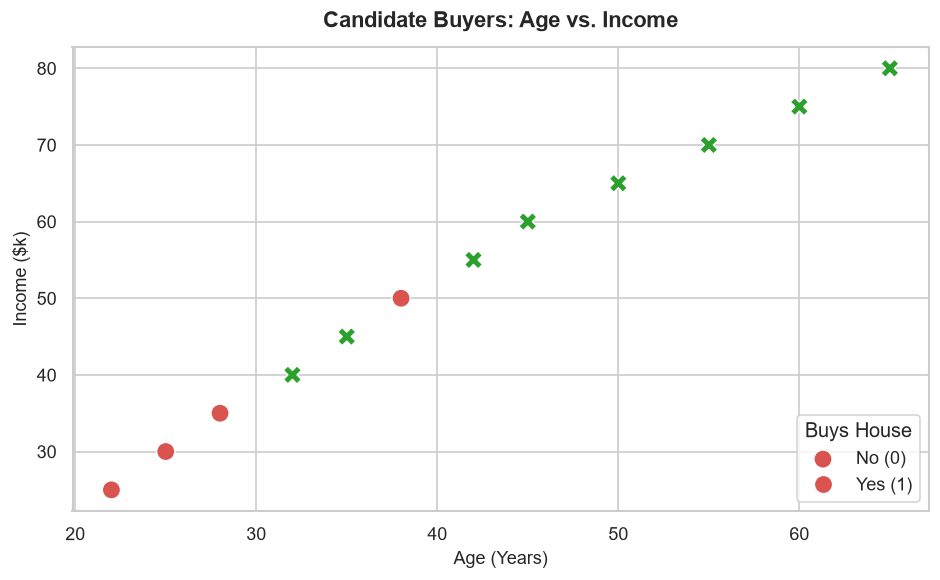

In [3]:
plt.figure(figsize=(8, 5))
scatter = sns.scatterplot(
    data=data,
    x='Age',
    y='Income',
    hue='Buys_House',
    style='Buys_House',
    s=120,
    palette={0: '#d9534f', 1: '#2ca02c'}
)

plt.title("Candidate Buyers: Age vs. Income", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Age (Years)", fontsize=11)
plt.ylabel("Income ($k)", fontsize=11)
plt.legend(title="Buys House", labels=["No (0)", "Yes (1)"], loc="lower right")
plt.tight_layout()
plt.show()


## 3. Decision Tree Model Training

We train a `DecisionTreeClassifier` with `criterion='gini'` and `max_depth=2` to ensure a concise, interpretable tree structure that prevents overfitting on small sample sizes.


In [4]:
# Separate feature matrix and target vector
X = data[['Age', 'Income']]
y = data['Buys_House']

# Initialize and fit the decision tree classifier
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=2,
    random_state=42
)
model.fit(X, y)

print("Decision Tree Model Trained Successfully.")
print(f"Root Split Feature: {X.columns[model.tree_.feature[0]]}")
print(f"Root Split Threshold: {model.tree_.threshold[0]:.2f}")
print(f"Tree Max Depth: {model.get_depth()}")
print(f"Number of Leaves: {model.get_n_leaves()}")


Decision Tree Model Trained Successfully.
Root Split Feature: Age
Root Split Threshold: 30.00
Tree Max Depth: 2
Number of Leaves: 3


## 4. Tree Architecture & Decision Rules

We visualize the learned tree using `plot_tree` and display the textual rules.


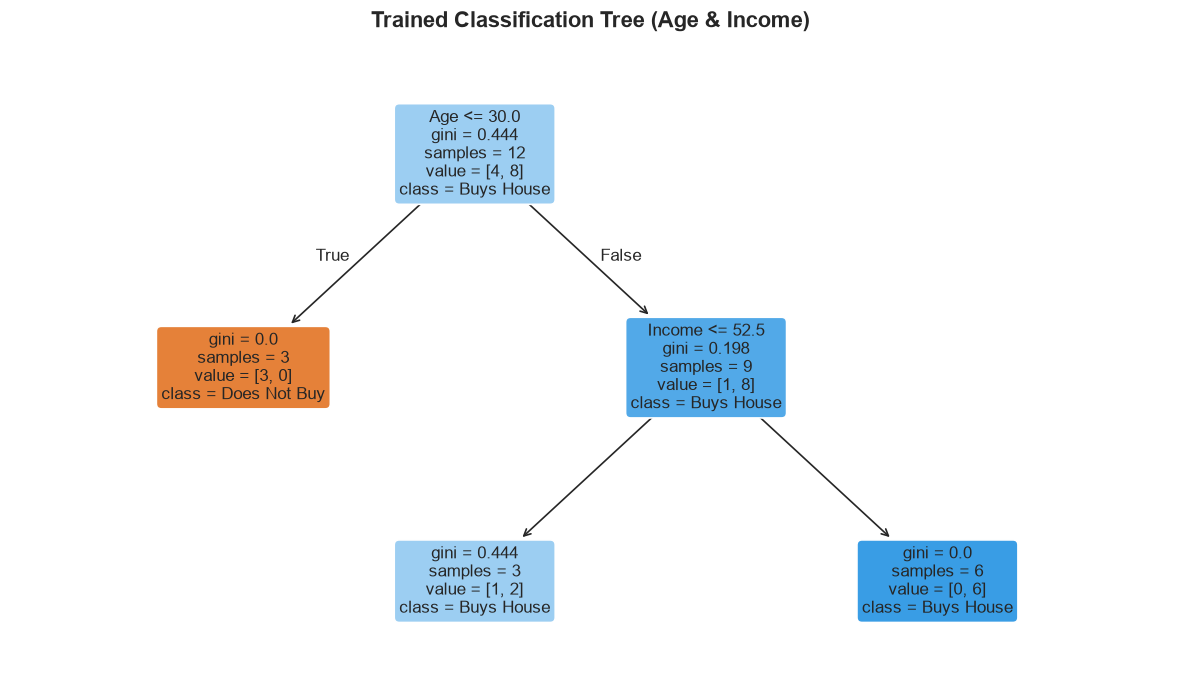

Learned Decision Rules:

|--- Age <= 30.00
|   |--- class: 0
|--- Age >  30.00
|   |--- Income <= 52.50
|   |   |--- class: 1
|   |--- Income >  52.50
|   |   |--- class: 1



In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_tree(
    model,
    feature_names=['Age', 'Income'],
    class_names=['Does Not Buy', 'Buys House'],
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False,
    ax=ax,
    fontsize=10
)
plt.title("Trained Classification Tree (Age & Income)", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# Textual Rule Representation
print("Learned Decision Rules:\n")
print(export_text(model, feature_names=['Age', 'Income']))


## 5. Model Evaluation & Decision Boundary Visualization

We assess model performance via training accuracy, confusion matrix, and a continuous decision boundary map across the 2D feature domain.


Model Accuracy on Training Set: 91.67%

Classification Report:
              precision    recall  f1-score   support

Does Not Buy       1.00      0.75      0.86         4
  Buys House       0.89      1.00      0.94         8

    accuracy                           0.92        12
   macro avg       0.94      0.88      0.90        12
weighted avg       0.93      0.92      0.91        12



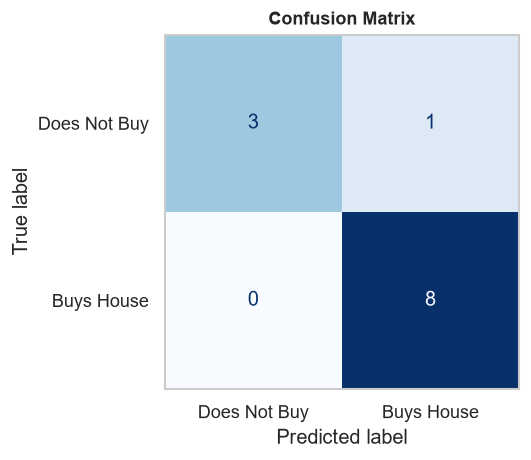

In [6]:
# Predictions and Performance Metrics
y_pred = model.predict(X)
acc = accuracy_score(y, y_pred)
cm = confusion_matrix(y, y_pred)

print(f"Model Accuracy on Training Set: {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y, y_pred, target_names=['Does Not Buy', 'Buys House']))

# Confusion Matrix Heatmap
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y,
    y_pred,
    display_labels=['Does Not Buy', 'Buys House'],
    cmap='Blues',
    ax=ax,
    colorbar=False
)
plt.title("Confusion Matrix", fontsize=11, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()


### 2D Decision Boundary Map
Decision trees construct orthogonal, step-like decision surfaces aligned with feature axes.


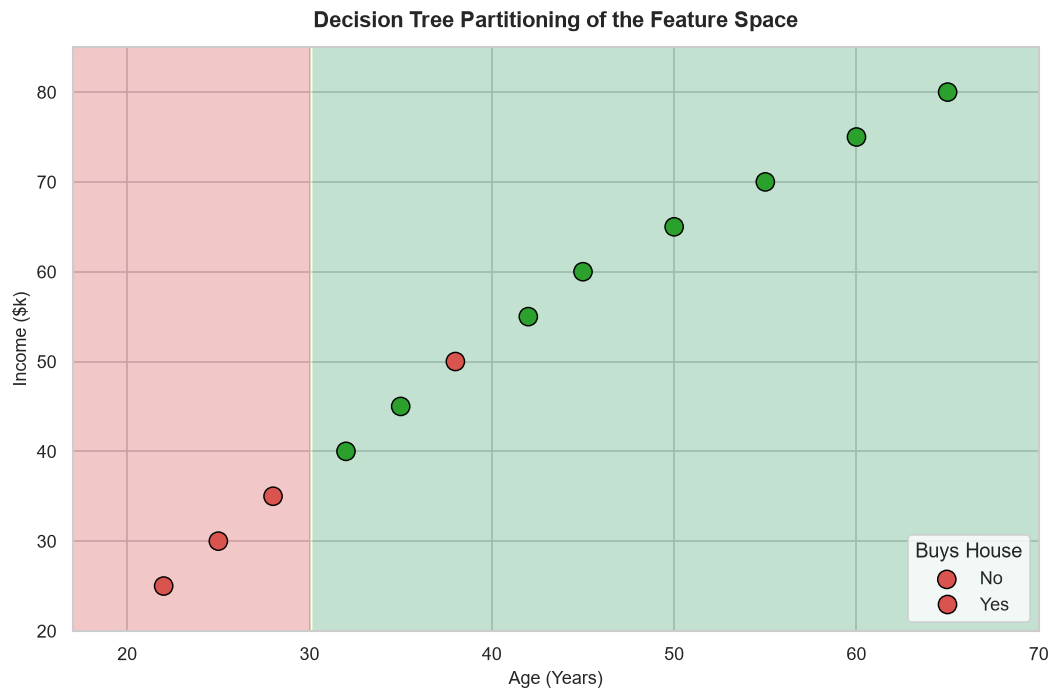

In [7]:
# Create dense grid across feature space
x_min, x_max = X['Age'].min() - 5, X['Age'].max() + 5
y_min, y_max = X['Income'].min() - 5, X['Income'].max() + 5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))

# Predict across meshgrid
grid_points = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=['Age', 'Income'])
Z = model.predict(grid_points).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap='RdYlGn')
scatter = sns.scatterplot(
    data=data,
    x='Age',
    y='Income',
    hue='Buys_House',
    palette={0: '#d9534f', 1: '#2ca02c'},
    s=120,
    edgecolor='black'
)
plt.title("Decision Tree Partitioning of the Feature Space", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Age (Years)", fontsize=11)
plt.ylabel("Income ($k)", fontsize=11)
plt.legend(title="Buys House", labels=["No", "Yes"], loc="lower right")
plt.tight_layout()
plt.show()


## 6. Inference on Unseen Instances

We evaluate model predictions on prospective buyer profiles:
1. Young buyer with modest income: Age = 24, Income = 28.
2. Mid-career buyer with solid income: Age = 36, Income = 62.
3. Senior buyer: Age = 52, Income = 45.


In [8]:
new_prospects = pd.DataFrame({
    'Age': [24, 36, 52],
    'Income': [28, 62, 45]
})

predictions = model.predict(new_prospects)
probabilities = model.predict_proba(new_prospects)

results = new_prospects.copy()
results['Predicted_Class'] = [
    'Does Not Buy' if p == 0 else 'Buys House' for p in predictions
]
results['Confidence_P(Buys)'] = probabilities[:, 1]

print("Inference on New Prospects:")
display(results)


Inference on New Prospects:


,Age,Income,Predicted_Class,Confidence_P(Buys)
0,24,28,Does Not Buy,0.000000
1,36,62,Buys House,1.000000
2,52,45,Buys House,0.666667


## 7. Observations & Conclusion

1. **Root Node Selection:** The tree identifies **Age $\le 30.0$** as the primary discriminator that yields the largest Gini impurity reduction.
2. **Subtree Partitioning:** For candidates older than 30, the tree evaluates **Income**, recognizing that higher-earning individuals in this demographic consistently purchase homes.
3. **Interpretability:** Unlike black-box models, the decision tree provides white-box boolean rules directly translatable into operational business logic.
4. **Generalization Consideration:** Constraining `max_depth=2` prevented the tree from isolating the single outlier (Age 38, Income 50), ensuring better generalization and avoiding overfitting.
